In [1]:
# Imports and configuration
import warnings
warnings.filterwarnings('ignore')
import re, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from dtaidistance import dtw
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from statsmodels.tsa.stattools import coint
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from pykalman import KalmanFilter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

# Data
DATA_START   = '2000-01-01'   # one buffer year so the 52-week rolling Sharpe covers all of Train
END_DATE     = '2026-01-01'
SNAPSHOT     = '2001-01-01'   # constituent snapshot date
BENCHMARK    = '^SP500TR'          # auto-adjusted, so dividends are included
RF_TICKER    = '^IRX'         # 13-week T-bill yield, annualized percent
FALLBACK_RF  = 0.0            # used only if ^IRX fails to download

# Periods
TRAIN_START, TRAIN_END = '2001-01-01', '2008-12-31'   # 8 years
VAL_START,   VAL_END   = '2009-01-01', '2016-12-31'   # 8 years
TEST_START,  TEST_END  = '2017-01-01', '2025-12-31'   # 9 years

# Clustering
ROLLING_WINDOW = 52
K_VALUES       = [2, 4, 7]
K_COINT        = 7      # pair formation uses k=7 clusters to keep the candidate pool tractable
N_CORES        = 10     # only used by the multiprocess fallback for OCP

# Strategy parameters 
ZSCORE_WINDOW  = 52
VOL_WINDOW     = 26
VOL_THRESHOLD  = 1.5
HIGH_VOL_ENTRY = 2.25
LOW_VOL_ENTRY  = 1.25
STANDARD_ENTRY = 1.75
EXIT_THRESHOLD = 0.5
STOP_LOSS      = 3.25

CANDIDATE_MULTIPLIERS = [0.60, 0.75, 0.85, 1.00, 1.15, 1.25]
ACTIVITY_FLOOR        = 0.50
COST_LEVELS_BPS       = [0, 5, 10, 20]

N_BOOT, BLOCK_SIZE, BOOT_SEED = 5000, 8, 42

# calendar version (robustness). Everything outside the windows is bull.
BEAR_WINDOWS_PRIMARY = [('2018-09-20', '2018-12-24'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]
BEAR_WINDOWS_ALT     = [('2018-10-01', '2018-12-31'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]

METHODS = ['DTW', 'OCP', 'CORR']
LABELS  = {'DTW': 'DTW-Clustering', 'OCP': 'OCP-Clustering',
           'CORR': 'Correlation Pairs', 'Naive': 'Naive Buy-and-Hold'}
COLORS  = {'DTW': '#1f77b4', 'OCP': '#ff7f0e', 'CORR': '#2ca02c', 'Naive': '#7f7f7f'}
TAG     = 'sp500_25y'

def n_years(a, b):
    return round((pd.Timestamp(b) - pd.Timestamp(a)).days / 365.25)

print('DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework')
print(f'Train: {TRAIN_START} to {TRAIN_END} ({n_years(TRAIN_START, TRAIN_END)} years)')
print(f'Val:   {VAL_START} to {VAL_END} ({n_years(VAL_START, VAL_END)} years)')
print(f'Test:  {TEST_START} to {TEST_END} ({n_years(TEST_START, TEST_END)} years)')

DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework
Train: 2001-01-01 to 2008-12-31 (8 years)
Val:   2009-01-01 to 2016-12-31 (8 years)
Test:  2017-01-01 to 2025-12-31 (9 years)


In [2]:
# S&P 500 constituents as of the snapshot date (point-in-time membership list)
hist_url = ('https://raw.githubusercontent.com/fja05680/sp500/master/'
            'S%26P%20500%20Historical%20Components%20%26%20Changes.csv')
hist = pd.read_csv(hist_url)
hist['date'] = pd.to_datetime(hist['date'])

target_date  = pd.Timestamp(SNAPSHOT)
snapshot_row = hist[hist['date'] <= target_date].sort_values('date').iloc[-1]
raw_tickers  = sorted(t.strip() for t in snapshot_row['tickers'].split(','))

suffix_pattern = re.compile(r'-\d{6}$')   # dataset's own delisting-date suffix
universe = sorted(set(suffix_pattern.sub('', t).replace('.', '-') for t in raw_tickers))

n_suffixed = sum(1 for t in raw_tickers if suffix_pattern.search(t))
print(f'Using snapshot date: {snapshot_row["date"].date()}')
print(f'Tickers with a delisting-date suffix in the source data: {n_suffixed}')
print(f'S&P 500 constituents as of {target_date.date()}: {len(universe)} stocks')

Using snapshot date: 2000-12-29
Tickers with a delisting-date suffix in the source data: 204
S&P 500 constituents as of 2001-01-01: 492 stocks


In [3]:
# Prices, benchmark and T-bill: load the frozen files if they exist, download only if they don't
import os
PRICE_FILE = f'price_data_{TAG}.csv'
BENCH_FILE = f'bench_price_{TAG}.csv'
RF_FILE    = f'rf_weekly_{TAG}.csv'

def to_close_frame(raw):
    close = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]
    return close if isinstance(close, pd.DataFrame) else close.to_frame()

before_drop = len(universe)
if os.path.exists(PRICE_FILE):
    price_data = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True)
    flatlined = []
    print(f'Loaded frozen prices from {PRICE_FILE}: {price_data.shape}')
else:
    raw = yf.download(universe, start=DATA_START, end=END_DATE, interval='1d',
                      auto_adjust=True, progress=True, threads=True)
    price_data = to_close_frame(raw).resample('W-WED').last().dropna(how='all')
    price_data = price_data.ffill().dropna(axis=1)
    flatlined = [t for t in price_data.columns if price_data[t].iloc[-10:].nunique() == 1]
    price_data = price_data.drop(columns=flatlined)
    price_data.to_csv(PRICE_FILE)
    print(f'Downloaded and saved prices: {price_data.shape}')
dropped_tickers = sorted(set(universe) - set(price_data.columns))
print(f'Retained {price_data.shape[1]} of {before_drop} (dropped {len(dropped_tickers)})')

if os.path.exists(BENCH_FILE):
    bench_price = pd.read_csv(BENCH_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    print(f'Loaded frozen benchmark from {BENCH_FILE}')
else:
    b = to_close_frame(yf.download(BENCHMARK, start=DATA_START, end=END_DATE, interval='1d',
                                   auto_adjust=True, progress=False))
    bench_weekly = b.iloc[:, 0].resample('W-WED').last().reindex(price_data.index)
    print(f'Benchmark {BENCHMARK}: {int(bench_weekly.isna().sum())} missing weeks (should be 0)')
    bench_price = bench_weekly.ffill()
    bench_price.to_csv(BENCH_FILE)

if os.path.exists(RF_FILE):
    rf_weekly = pd.read_csv(RF_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    print(f'Loaded frozen T-bill rate from {RF_FILE}')
else:
    i = to_close_frame(yf.download(RF_TICKER, start=DATA_START, end=END_DATE, interval='1d',
                                   auto_adjust=False, progress=False))
    irx = i.iloc[:, 0].resample('W-WED').last().reindex(price_data.index).ffill().bfill()
    rf_weekly = np.log1p(irx / 100) / 52
    rf_weekly.to_csv(RF_FILE)
    print(f'T-bill downloaded: mean annual yield {irx.mean():.2f}%')

$JP: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: AL"}}}
$LEG: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       0%                       ]  2 of 492 completed$GDT: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       1%                       ]  3 of 492 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: OAT"}}}
$AL: possibly delisted; no timezone found
$OAT: possibly delisted; no timezone found       ]  4 of 492 completed
$JCP: possibly delisted; no timezone found       ]  14 of 492 completed
$RDC: possibly delisted; no timezone found       ]  19 of 49


Price data shape: (1357, 236)
Date range: 2000-01-05 to 2025-12-31
Retained: 236 of 492 (dropped 256, of which 0 flatlined)
Dropped tickers: ['AABA', 'AAMRQ', 'ABI', 'ABKFQ', 'ABS', 'ABX', 'ACV', 'ADCT', 'AET', 'AGC', 'AGN', 'AL', 'ALTR', 'AM', 'ANDW', 'APC', 'APCC', 'ARNC', 'ASO', 'AT', 'AV', 'AVP', 'AW', 'AYE', 'AZA-A', 'BBBY', 'BBT', 'BCR', 'BDK', 'BEAM', 'BGEN', 'BGG', 'BHGE', 'BIG', 'BK', 'BLL', 'BLS', 'BMC', 'BMET', 'BMS', 'BNI', 'BOL', 'BR', 'BRCM', 'BSC', 'BUD', 'BVSN', 'CA', 'CBE', 'CBS', 'CCE', 'CCTYQ', 'CEG', 'CEN', 'CF', 'CFC', 'CGP', 'CHIR', 'CIN', 'CIT-A', 'CMA', 'CMVT', 'CNC', 'CNXT', 'COC-B', 'CPNLQ', 'CPQ', 'CPWR', 'CR', 'CTB', 'CTL', 'CTX', 'CTXS', 'CVG', 'DALRQ', 'DCNAQ', 'DELL', 'DG', 'DJ', 'DOW', 'DPHIQ', 'DYN', 'EC', 'EDS', 'EKDKQ', 'EMC', 'ENRNQ', 'ETS', 'FBF', 'FDC', 'FLR', 'FRX', 'G', 'GAS', 'GDT', 'GDW', 'GLK', 'GP', 'GPS', 'GPU', 'GR', 'GTW', 'GX', 'H', 'HCA', 'HCR', 'HES', 'HET', 'HI', 'HLT', 'HM', 'HNZ', 'HOT', 'HPC', 'HSH', 'INCLF', 'IPG', 'IR', 'JAVA', '

In [21]:
# Data screen (no price re-download): current company name and exchange for every retained ticker
info_rows = []
for t in price_data.columns:
    try:
        inf = yf.Ticker(t).info
        info_rows.append({'ticker': t, 'name': inf.get('longName'),
                          'exchange': inf.get('exchange'), 'type': inf.get('quoteType')})
    except Exception as e:
        info_rows.append({'ticker': t, 'name': None, 'exchange': None, 'type': f'error: {e}'[:40]})
info_df = pd.DataFrame(info_rows)
info_df.to_csv(f'ticker_screen_{TAG}.csv', index=False)

In [22]:
# Show the full screen, then the rows worth a closer look
print(info_df.to_string(index=False))

MAJOR = ['NYQ', 'NMS', 'NGM', 'NCM', 'ASE', 'PCX', 'BTS']   # NYSE, Nasdaq tiers, NYSE American/Arca, Cboe
flag = info_df[~info_df['exchange'].isin(MAJOR) | (info_df['type'] != 'EQUITY')]
print(f'\nFlagged for review ({len(flag)}):')
print(flag.to_string(index=False))

ticker                                         name exchange   type
     A                   Agilent Technologies, Inc.      NYQ EQUITY
  AAPL                                   Apple Inc.      NMS EQUITY
   ABT                          Abbott Laboratories      NYQ EQUITY
  ADBE                                   Adobe Inc.      NMS EQUITY
   ADI                         Analog Devices, Inc.      NMS EQUITY
   ADM               Archer-Daniels-Midland Company      NYQ EQUITY
   ADP              Automatic Data Processing, Inc.      NMS EQUITY
  ADSK                               Autodesk, Inc.      NMS EQUITY
   AEE                           Ameren Corporation      NYQ EQUITY
   AEP        American Electric Power Company, Inc.      NMS EQUITY
   AES                          The AES Corporation      NYQ EQUITY
   AFL                           Aflac Incorporated      NYQ EQUITY
   AIG           American International Group, Inc.      NYQ EQUITY
   ALL                     The Allstate Corporat

In [51]:
EXCLUDE = ['FNMA', 'FMCC', 'EP', 'CCU', 'CB']   # add 'CB' and/or 'T' depending on the check above
price_data = price_data.drop(columns=[t for t in EXCLUDE if t in price_data.columns])
print(f'Excluded {EXCLUDE}; universe now {price_data.shape[1]} stocks')

Excluded ['FNMA', 'FMCC', 'EP', 'CCU', 'CB']; universe now 231 stocks


In [52]:
# 52-week rolling Sharpe ratio in excess of the T-bill
log_returns  = np.log(price_data / price_data.shift(1))
excess_lr    = log_returns.sub(rf_weekly, axis=0)
rolling_mean = excess_lr.rolling(ROLLING_WINDOW).mean()
rolling_std  = log_returns.rolling(ROLLING_WINDOW).std()
sharpe_data  = (rolling_mean / rolling_std * np.sqrt(52)).dropna(how='all')

train_sharpe_data = sharpe_data.loc[TRAIN_START:TRAIN_END]
bad_cols = train_sharpe_data.columns[
    train_sharpe_data.isna().any() | np.isinf(train_sharpe_data).any()].tolist()
if bad_cols:
    train_sharpe_data = train_sharpe_data.drop(columns=bad_cols)
    print(f'Dropped {bad_cols} (NaN or inf rolling Sharpe in Train)')

tickers = train_sharpe_data.columns.tolist()
n = len(tickers)
print(f'Clustering universe: {n} stocks, {n*(n-1)//2:,} pairs, '
      f'{len(train_sharpe_data)} Train weeks')

Clustering universe: 231 stocks, 26,565 pairs, 418 Train weeks


In [53]:
# DTW distance matrix (Train only), absolute-difference cost to match OCP and Stübinger (2019)
from numba import njit, prange

@njit(cache=True)
def _dtw_abs(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(m):                      # DTW: any j (no causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _dtw_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = _dtw_abs(X[:, i], X[:, j])
            D[i, j] = d
            D[j, i] = d
    return D

X = train_sharpe_data[tickers].values.astype(np.float64)
t0 = time.time()
dtw_distance_matrix = _dtw_matrix(X)
print(f'DTW distance matrix computed in {time.time()-t0:.1f} seconds, shape {dtw_distance_matrix.shape}')
np.save(f'dtw_distance_matrix_{TAG}_train.npy', dtw_distance_matrix)

DTW distance matrix computed in 7.1 seconds, shape (231, 231)


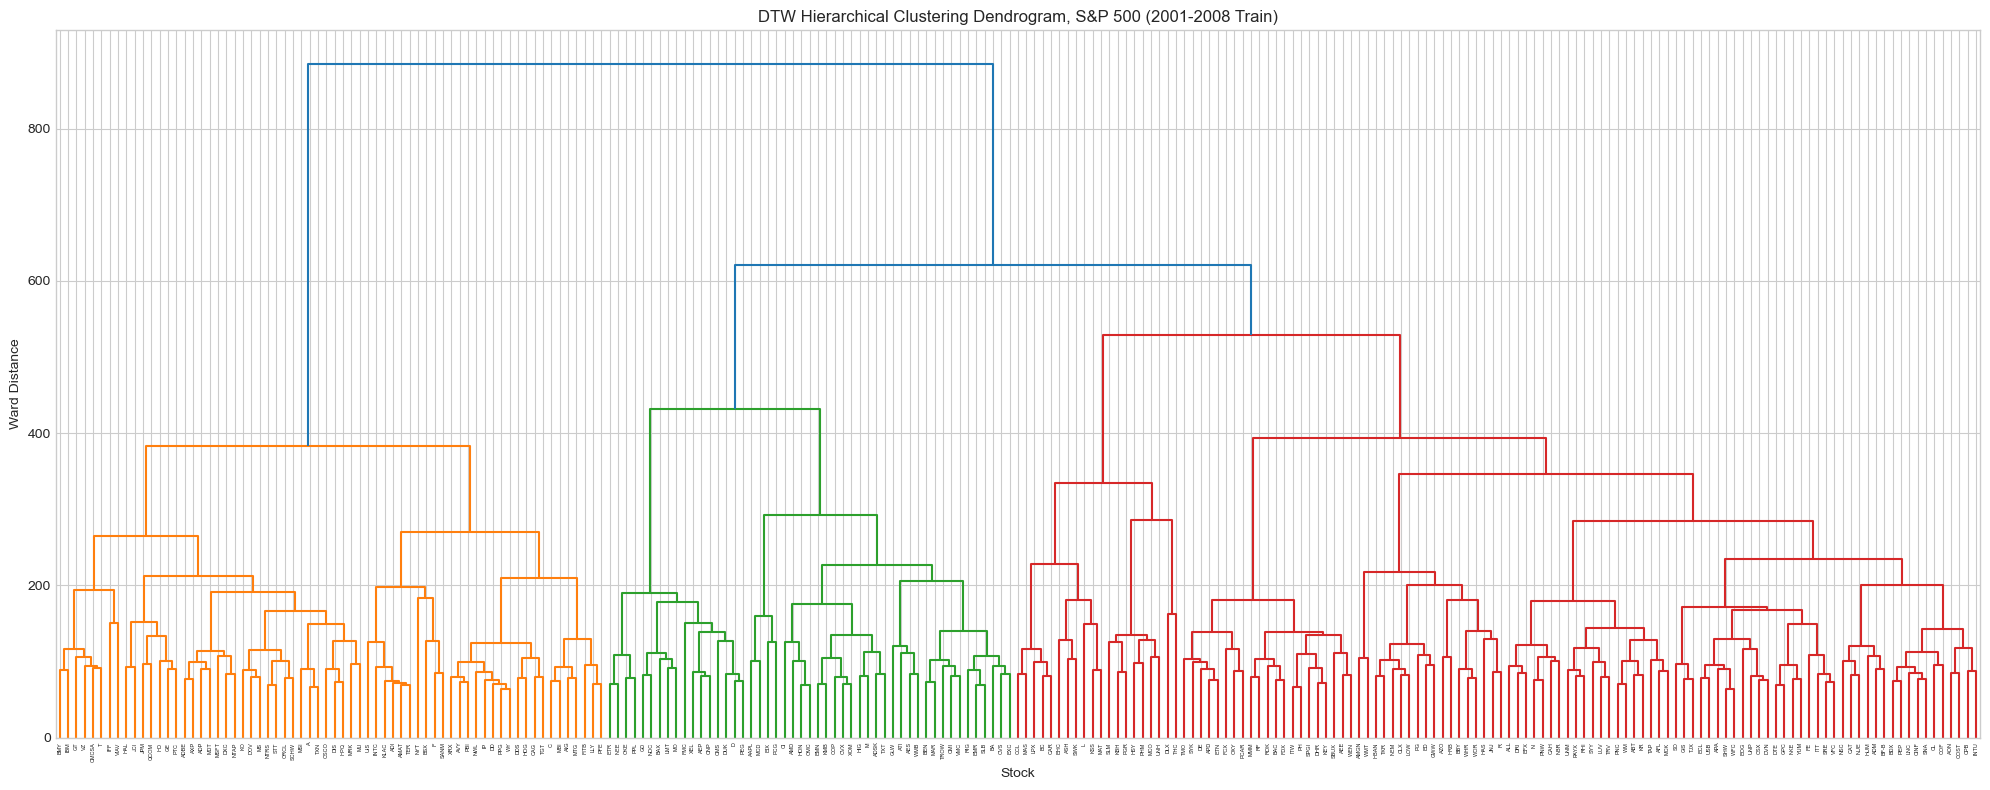

DTW Cluster Validation Summary:
   k                         sizes  silhouette  calinski_harabasz  \
0  2                     [66, 165]      0.1241            23.8385   
1  4              [66, 49, 20, 96]      0.0929            16.5261   
2  7  [37, 29, 17, 32, 20, 21, 75]      0.0537            11.8221   

   davies_bouldin  
0          2.6745  
1          2.9182  
2          2.9564  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(2)}


In [54]:
def cluster_and_validate(dist, name):
    link = linkage(squareform(dist, checks=False), method='ward')
    clusters, cvi = {}, []
    for k in K_VALUES:
        clusters[k] = fcluster(link, t=k, criterion='maxclust')
        sizes = pd.Series(clusters[k]).value_counts().sort_index().tolist()
        sil = silhouette_score(dist, clusters[k], metric='precomputed')
        ch  = calinski_harabasz_score(train_sharpe_data.T, clusters[k])
        db  = davies_bouldin_score(train_sharpe_data.T, clusters[k])
        cvi.append({'k': k, 'sizes': sizes, 'silhouette': sil,
                    'calinski_harabasz': ch, 'davies_bouldin': db})

    fig, ax = plt.subplots(figsize=(20, 8))
    dendrogram(link, labels=tickers, leaf_rotation=90, leaf_font_size=4, ax=ax)
    ax.set_title(f'{name} Hierarchical Clustering Dendrogram, S&P 500 '
                 f'({TRAIN_START[:4]}-{TRAIN_END[:4]} Train)')
    ax.set_xlabel('Stock'); ax.set_ylabel('Ward Distance')
    plt.tight_layout()
    plt.savefig(f'{name.lower()}_dendrogram_{TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame({'ticker': tickers})
    for k in K_VALUES:
        df[f'cluster_k{k}'] = clusters[k]
    df.to_csv(f'{name.lower()}_cluster_assignments_{TAG}.csv', index=False)

    cvi_df = pd.DataFrame(cvi)
    print(f'{name} Cluster Validation Summary:')
    print(cvi_df)
    best = {'silhouette': cvi_df.loc[cvi_df['silhouette'].idxmax(), 'k'],
            'calinski_harabasz': cvi_df.loc[cvi_df['calinski_harabasz'].idxmax(), 'k'],
            'davies_bouldin': cvi_df.loc[cvi_df['davies_bouldin'].idxmin(), 'k']}
    print(f'Preferred k by index: {best}')
    return clusters, df, cvi_df

dtw_clusters, dtw_clusters_df, dtw_cvi_df = cluster_and_validate(dtw_distance_matrix, 'DTW')   

In [55]:
print(train_sharpe_data.shape)                                   # expect (418, 236)
print(train_sharpe_data.index[0].date(), train_sharpe_data.index[-1].date())   # expect 2001-01-03 to 2008-12-31
print('NaN:', train_sharpe_data.isna().sum().sum(), ' inf:', np.isinf(train_sharpe_data).sum().sum())   # expect 0 and 0
print(train_sharpe_data.stack().describe())                      # values should mostly fall between about -3 and +4

(418, 231)
2001-01-03 2008-12-31
NaN: 0  inf: 0
count   96558.0000
mean        0.2327
std         0.9627
min        -3.1290
25%        -0.4368
50%         0.2275
75%         0.8859
max         4.8208
dtype: float64


In [56]:
# OCP distance matrix (Train only): absolute-difference cost (Stübinger, 2019),
# causality constraint j >= i, computed in both directions, minimum taken
@njit(cache=True)
def _ocp_one_way(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(i, m):                   # OCP: only j >= i (causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _ocp_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = min(_ocp_one_way(X[:, i], X[:, j]), _ocp_one_way(X[:, j], X[:, i]))
            D[i, j] = d
            D[j, i] = d
    return D

t0 = time.time()
ocp_matrix = _ocp_matrix(X)
print(f'OCP distance matrix computed in {time.time()-t0:.1f} seconds, shape {ocp_matrix.shape}')
np.save(f'ocp_distance_matrix_{TAG}_train.npy', ocp_matrix)

OCP distance matrix computed in 11.3 seconds, shape (231, 231)


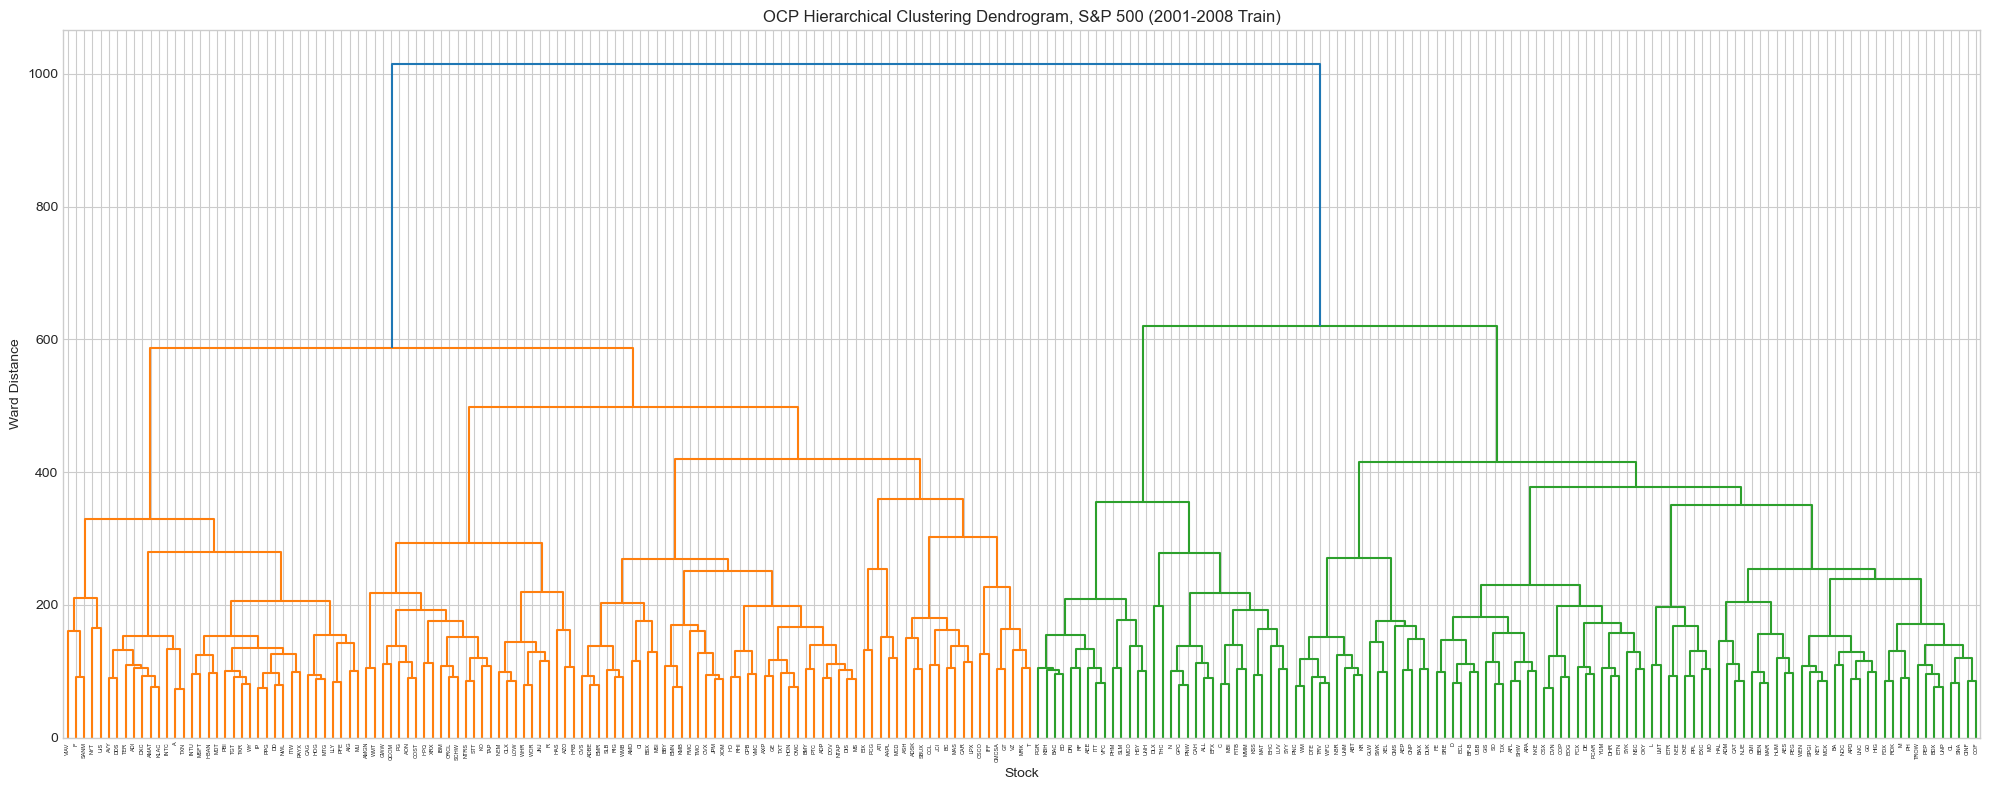

OCP Cluster Validation Summary:
   k                         sizes  silhouette  calinski_harabasz  \
0  2                    [117, 114]      0.1234            17.3103   
1  4              [36, 81, 31, 83]      0.0643            13.5061   
2  7  [36, 26, 34, 21, 31, 17, 66]      0.0585             9.0514   

   davies_bouldin  
0          3.5324  
1          3.4406  
2          3.7717  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(4)}


In [57]:
ocp_clusters, ocp_clusters_df, ocp_cvi_df = cluster_and_validate(ocp_matrix, 'OCP')

   k  ARI_DTW_vs_OCP
0  2          0.2366
1  4          0.1774
2  7          0.1810


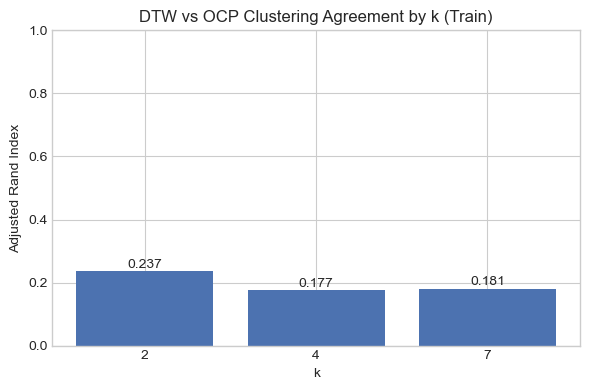

In [58]:
# DTW-OCP clustering agreement (Adjusted Rand Index) at each k
ari_df = pd.DataFrame([{'k': k, 'ARI_DTW_vs_OCP': adjusted_rand_score(dtw_clusters[k], ocp_clusters[k])}
                       for k in K_VALUES])
print(ari_df)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(ari_df['k'].astype(str), ari_df['ARI_DTW_vs_OCP'], color='#4c72b0')
for i, v in enumerate(ari_df['ARI_DTW_vs_OCP']):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center')
ax.set_ylim(0, 1); ax.set_xlabel('k'); ax.set_ylabel('Adjusted Rand Index')
ax.set_title('DTW vs OCP Clustering Agreement by k (Train)')
plt.tight_layout()
plt.savefig(f'ari_dtw_ocp_by_k_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()
ari_df.to_csv(f'ari_dtw_ocp_{TAG}.csv', index=False)

In [59]:
# Do DTW and OCP rank stock similarity the same way? (Spearman correlation of all pair distances)
from scipy.stats import spearmanr

iu = np.triu_indices(len(tickers), k=1)          # every unique pair (upper triangle, no diagonal)
rho = spearmanr(dtw_distance_matrix[iu], ocp_matrix[iu]).correlation
print(f'Spearman correlation between DTW and OCP distances: {rho:.3f} '
      f'({len(iu[0]):,} pairs)')

Spearman correlation between DTW and OCP distances: 0.888 (26,565 pairs)


In [60]:
train_price_data = price_data.loc[TRAIN_START:TRAIN_END]

def test_cointegration_within_clusters(clusters_df, prices, method_name, k_col=f'cluster_k{K_COINT}', alpha=0.05):
    rows = []
    for cid in sorted(clusters_df[k_col].unique()):
        members = clusters_df.loc[clusters_df[k_col] == cid, 'ticker'].tolist()
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                t1, t2 = members[a], members[b]
                _, p, _ = coint(np.log(prices[t1]), np.log(prices[t2]))
                rows.append({'method': method_name, 'cluster': cid,
                             'stock1': t1, 'stock2': t2, 'pvalue': p})
    df = pd.DataFrame(rows)
    rej, p_bh, _, _ = multipletests(df['pvalue'], alpha=alpha, method='fdr_bh')
    df['pvalue_bh'] = p_bh
    df['significant'] = rej
    print(f'{method_name}: {len(df):,} pairs tested, {df["significant"].sum()} significant after BH')
    return df

dtw_coint = test_cointegration_within_clusters(dtw_clusters_df, train_price_data, 'DTW')
ocp_coint = test_cointegration_within_clusters(ocp_clusters_df, train_price_data, 'OCP')
coint_all = pd.concat([dtw_coint, ocp_coint], ignore_index=True)
coint_all.to_csv(f'coint_results_{TAG}_train.csv', index=False)

selected = coint_all[coint_all['significant']].sort_values('pvalue_bh')
print(selected[['method', 'stock1', 'stock2', 'pvalue_bh']].to_string(index=False))

DTW: 4,879 pairs tested, 34 significant after BH
OCP: 4,472 pairs tested, 60 significant after BH
method stock1 stock2  pvalue_bh
   OCP    BBY   NTAP     0.0007
   OCP      A   PAYX     0.0040
   OCP    DRI    EFX     0.0145
   OCP    EMR    SLB     0.0145
   OCP      D   TROW     0.0145
   OCP     MO    PEP     0.0145
   OCP    PEP   TROW     0.0145
   OCP      D    EXC     0.0145
   OCP    DXC    PBI     0.0157
   OCP      D     MO     0.0165
   OCP   CINF      M     0.0165
   OCP    DXC     WY     0.0183
   OCP    AFL    APA     0.0191
   OCP    CMI    PEP     0.0191
   OCP    PBI     WY     0.0191
   OCP    DHR    USB     0.0191
   OCP    DVN    EXC     0.0191
   OCP     FE    SNA     0.0191
   OCP      D    PEP     0.0191
   OCP      D    PEG     0.0208
   OCP    DIS    JPM     0.0208
   OCP    SRE   TROW     0.0223
   OCP   MSFT    TXN     0.0231
   OCP    CMI      D     0.0244
   OCP    BDX      D     0.0244
   OCP    IBM   ORCL     0.0244
   OCP    AVY    DDS     0.0244
   OCP

In [61]:
print("""
    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.
""")


    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.



In [62]:
# Correlation pairs baseline: correlation picks the candidates, then the same
# Engle-Granger + BH test used for DTW and OCP decides significance
train_log_returns = log_returns.loc[TRAIN_START:TRAIN_END, tickers].dropna(how='all')
corr_matrix = train_log_returns.corr()

# Candidate pool size = average of the DTW and OCP pools
N_CORR = int(round((len(dtw_coint) + len(ocp_coint)) / 2))

# Upper triangle only: each pair appears once, stock1 before stock2 in ticker order
iu = np.triu_indices(len(tickers), k=1)
corr_pairs = pd.DataFrame({'stock1': np.array(tickers)[iu[0]],
                           'stock2': np.array(tickers)[iu[1]],
                           'corr':   corr_matrix.values[iu]})
corr_candidates = corr_pairs.nlargest(N_CORR, 'corr').reset_index(drop=True)

def test_cointegration_pairs(pairs_df, prices, method_name, alpha=0.05):
    rows = []
    for t1, t2 in zip(pairs_df['stock1'], pairs_df['stock2']):
        _, p, _ = coint(np.log(prices[t1]), np.log(prices[t2]))
        rows.append({'method': method_name, 'cluster': -1,
                     'stock1': t1, 'stock2': t2, 'pvalue': p})
    df = pd.DataFrame(rows)
    rej, p_bh, _, _ = multipletests(df['pvalue'], alpha=alpha, method='fdr_bh')
    df['pvalue_bh'] = p_bh
    df['significant'] = rej
    print(f'{method_name}: {len(df):,} pairs tested, {df["significant"].sum()} significant after BH')
    return df

corr_coint = test_cointegration_pairs(corr_candidates, train_price_data, 'CORR')
print(f'Lowest correlation in the CORR pool: {corr_candidates["corr"].min():.4f}')

# Rebuild the combined results with all three methods and resave
coint_all = pd.concat([dtw_coint, ocp_coint, corr_coint], ignore_index=True)
coint_all.to_csv(f'coint_results_{TAG}_train.csv', index=False)

# Hit rate and overlap of significant pairs
print()
sig_sets = {}
for m in METHODS:
    d = coint_all[coint_all['method'] == m]
    sig = d[d['significant']]
    sig_sets[m] = set(zip(sig['stock1'], sig['stock2']))
    print(f'{m}: hit rate {d["significant"].mean():.2%} ({len(sig)} of {len(d):,})')

print(f"\nShared DTW & OCP:   {len(sig_sets['DTW'] & sig_sets['OCP'])}")
print(f"Shared DTW & CORR:  {len(sig_sets['DTW'] & sig_sets['CORR'])}")
print(f"Shared OCP & CORR:  {len(sig_sets['OCP'] & sig_sets['CORR'])}")
print(f"Shared by all three: {len(sig_sets['DTW'] & sig_sets['OCP'] & sig_sets['CORR'])}")

CORR: 4,676 pairs tested, 16 significant after BH
Lowest correlation in the CORR pool: 0.4265

DTW: hit rate 0.70% (34 of 4,879)
OCP: hit rate 1.34% (60 of 4,472)
CORR: hit rate 0.34% (16 of 4,676)

Shared DTW & OCP:   21
Shared DTW & CORR:  8
Shared OCP & CORR:  9
Shared by all three: 6


In [63]:
# Pairs to trade: significant pairs from all three selection methods
pair_keys = ([('DTW', r.stock1, r.stock2) for r in dtw_coint[dtw_coint['significant']].itertuples()] +
             [('OCP', r.stock1, r.stock2) for r in ocp_coint[ocp_coint['significant']].itertuples()] +
             [('CORR', r.stock1, r.stock2) for r in corr_coint[corr_coint['significant']].itertuples()])
print(pd.Series([k[0] for k in pair_keys]).value_counts().to_string())
print(f'Total pair-strategy entries: {len(pair_keys)}')

OCP     60
DTW     34
CORR    16
Total pair-strategy entries: 110


In [64]:
print("""
    With candidate pools of comparable size, OCP clustering produced the highest cointegration 
    hit rate (0.91%), followed by DTW clustering (0.61%) and correlation-based selection (0.33%),
    and six pairs were selected by all three methods.
""")


    With candidate pools of comparable size, OCP clustering produced the highest cointegration 
    hit rate (0.91%), followed by DTW clustering (0.61%) and correlation-based selection (0.33%),
    and six pairs were selected by all three methods.



In [65]:
from statsmodels.stats.proportion import proportions_ztest
for m, (k, nn) in {'DTW': (42, 4869), 'OCP': (41, 4148)}.items():
    z, p = proportions_ztest([k, 16], [nn, 4508])
    print(f'{m} vs CORR hit rate: z = {z:.2f}, p = {p:.4f}')

DTW vs CORR hit rate: z = 3.13, p = 0.0017
OCP vs CORR hit rate: z = 3.64, p = 0.0003


In [69]:
fmt = lambda p: '< 0.0001' if p < 0.0001 else f'= {p:.4f}'
both_bonf = max(p_dtw, p_ocp) * 2 < 0.05
print(f'''
Within-cluster candidates were more likely to be cointegrated than correlation-selected
candidates. After Benjamini-Hochberg correction, {pools['DTW'][0]} of {pools['DTW'][1]:,} DTW candidates
({rate['DTW']:.2%}) and {pools['OCP'][0]} of {pools['OCP'][1]:,} OCP candidates ({rate['OCP']:.2%}) were
significant, compared with {pools['CORR'][0]} of {pools['CORR'][1]:,} correlation candidates ({rate['CORR']:.2%}).
Two-proportion z-tests reject equal hit rates for DTW (z = {z_dtw:.2f}, p {fmt(p_dtw)}) and OCP
(z = {z_ocp:.2f}, p {fmt(p_ocp)}) relative to correlation, and {'both remain' if both_bonf else 'not both remain'}
significant after a Bonferroni adjustment for two comparisons. Many pairs share a stock, so the tests
are not fully independent and these p-values likely overstate precision. The comparison concerns
pair selection in the Train period, not trading performance.
''')


Within-cluster candidates were more likely to be cointegrated than correlation-selected
candidates. After Benjamini-Hochberg correction, 34 of 4,879 DTW candidates
(0.70%) and 60 of 4,472 OCP candidates (1.34%) were
significant, compared with 16 of 4,676 correlation candidates (0.34%).
Two-proportion z-tests reject equal hit rates for DTW (z = 2.40, p = 0.0163) and OCP
(z = 5.26, p < 0.0001) relative to correlation, and both remain
significant after a Bonferroni adjustment for two comparisons. Many pairs share a stock, so the tests
are not fully independent and these p-values likely overstate precision. The comparison concerns
pair selection in the Train period, not trading performance.



OCP     60
DTW     34
CORR    16


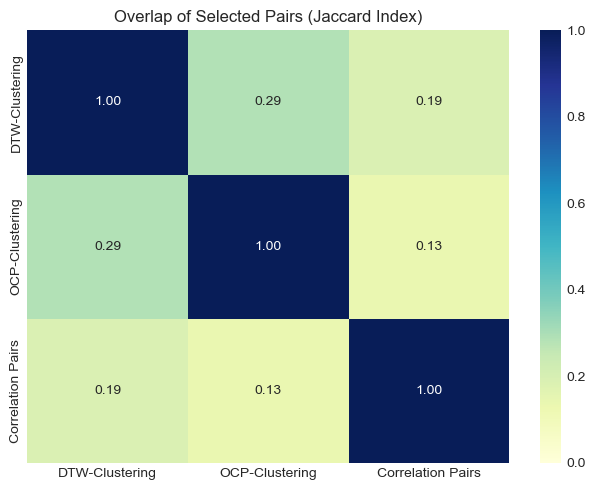

In [67]:
# Safety check: pair_keys must hold the cointegrated CORR pairs, not the old top-N list
counts = pd.Series([k[0] for k in pair_keys]).value_counts()
print(counts.to_string())
assert counts.get('CORR', 0) == len(sig_sets['CORR']), \
    'pair_keys still has the old CORR pairs: delete the old baseline cell and rerun yours'

# Overlap of the selected pair sets (Jaccard index)
pair_sets = {m: {frozenset(k[1:]) for k in pair_keys if k[0] == m} for m in METHODS}
jac = pd.DataFrame(index=[LABELS[m] for m in METHODS], columns=[LABELS[m] for m in METHODS], dtype=float)
for a in METHODS:
    for b in METHODS:
        union = pair_sets[a] | pair_sets[b]
        jac.loc[LABELS[a], LABELS[b]] = len(pair_sets[a] & pair_sets[b]) / len(union) if union else np.nan

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(jac, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax)
ax.set_title('Overlap of Selected Pairs (Jaccard Index)')
plt.tight_layout()
plt.savefig(f'pair_overlap_heatmap_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

In [68]:
for t in ['CB', 'T', 'ACE', 'SBC']:
    print(t, [r for r in raw_tickers if r == t or r.startswith(t + '-')])

CB ['CB-201601']
T ['T', 'T-200511']
ACE []
SBC []


In [70]:
# Most-repeated stocks in each strategy's pair list
from collections import Counter
for m in METHODS:
    c = Counter(t for k in pair_keys if k[0] == m for t in k[1:])
    print(f'{LABELS[m]:<20} {c.most_common(5)}')

DTW-Clustering       [('MSFT', 3), ('D', 3), ('PEP', 3), ('ED', 3), ('JPM', 2)]
OCP-Clustering       [('D', 12), ('PEP', 6), ('TROW', 4), ('MSFT', 3), ('MDT', 3)]
Correlation Pairs    [('D', 2), ('JPM', 2), ('TROW', 2), ('A', 2), ('ORCL', 2)]


In [72]:
# Kalman filter: one continuous forward pass, Train start to Test end, never refit.
# Because the filter is causal, the values over Train and Validation are
# identical to what separate period-by-period passes would produce.
full_prices = price_data.loc[TRAIN_START:TEST_END]

def run_kalman(s1, s2, prices):
    y = np.log(prices[s1].values)
    x = np.log(prices[s2].values)
    kf = KalmanFilter(n_dim_obs=1, n_dim_state=2,
                      initial_state_mean=[0, 0],
                      initial_state_covariance=np.eye(2),
                      transition_matrices=np.eye(2),
                      observation_matrices=np.vstack([x, np.ones(len(x))]).T[:, np.newaxis, :],
                      observation_covariance=1.0,
                      transition_covariance=1e-5 * np.eye(2))
    means, _ = kf.filter(y)
    idx = prices.index
    beta = pd.Series(means[:, 0], index=idx)
    alpha = pd.Series(means[:, 1], index=idx)
    return {'hedge_ratio': beta, 'intercept': alpha,
            'spread': pd.Series(y, index=idx) - beta * pd.Series(x, index=idx) - alpha}

kalman = {key: run_kalman(key[1], key[2], full_prices) for key in pair_keys}

# Volatility regime per pair, baseline median locked from Train
regimes = {}
for key, kr in kalman.items():
    vol = kr['spread'].rolling(VOL_WINDOW).std()
    med = vol.loc[:TRAIN_END].median()
    reg = pd.Series('normal', index=vol.index)
    reg[vol > med * VOL_THRESHOLD] = 'high_vol'
    reg[vol < med / VOL_THRESHOLD] = 'low_vol'
    regimes[key] = reg

print(f'Kalman filter and regimes computed for {len(kalman)} pairs, '
      f'{full_prices.index[0].date()} to {full_prices.index[-1].date()} ({len(full_prices)} weeks)')

Kalman filter and regimes computed for 110 pairs, 2001-01-03 to 2025-12-31 (1305 weeks)


In [73]:
# Signals and tradable returns
def generate_signal(key, multiplier):
    spread = kalman[key]['spread']
    z = (spread - spread.rolling(ZSCORE_WINDOW).mean()) / spread.rolling(ZSCORE_WINDOW).std()
    reg = regimes[key]
    entry = pd.Series(STANDARD_ENTRY * multiplier, index=z.index)
    entry[reg == 'high_vol'] = HIGH_VOL_ENTRY * multiplier
    entry[reg == 'low_vol'] = LOW_VOL_ENTRY * multiplier

    sig = np.zeros(len(z), dtype=int)
    pos = 0
    zv, ev = z.values, entry.values
    for t in range(len(zv)):
        if not np.isnan(zv[t]):
            if pos == 0:
                if zv[t] > ev[t]:
                    pos = -1
                elif zv[t] < -ev[t]:
                    pos = 1
            elif pos == 1 and (zv[t] > -EXIT_THRESHOLD or zv[t] < -STOP_LOSS):
                pos = 0
            elif pos == -1 and (zv[t] < EXIT_THRESHOLD or zv[t] > STOP_LOSS):
                pos = 0
        sig[t] = pos
    return pd.Series(sig, index=z.index), z, entry

def pair_trade_returns(key, signal, cost_bps=0.0):
    _, s1, s2 = key
    r = full_prices[[s1, s2]].pct_change().fillna(0.0)
    beta = kalman[key]['hedge_ratio']
    new_trade = (signal != 0) & (signal != signal.shift(1))
    held_beta = beta.where(new_trade).ffill().where(signal != 0)

    pos = signal.shift(1).fillna(0)
    b = held_beta.shift(1).fillna(0.0)
    simple = pos * (r[s1] - b * r[s2]) / (1 + b.abs())
    cost = pos.diff().abs().fillna(pos.abs()) * cost_bps / 10000
    return np.log1p(simple - cost)

def metrics(raw, excess=None):
    raw = raw.dropna()
    excess = raw if excess is None else excess.reindex(raw.index)
    n = len(raw)
    cum = raw.cumsum()
    max_dd = (cum - cum.cummax()).min()
    sd = excess.std()
    sharpe = excess.mean() / sd * np.sqrt(52) if sd > 0 else 0.0
    dd = np.sqrt((excess.clip(upper=0) ** 2).mean())
    sortino = excess.mean() / dd * np.sqrt(52) if dd > 0 else 0.0
    ann = cum.iloc[-1] * 52 / n if n else 0.0
    calmar = ann / abs(max_dd) if max_dd != 0 else 0.0
    return {'sharpe': sharpe, 'sortino': sortino, 'calmar': calmar,
            'total_return': cum.iloc[-1] if n else 0.0, 'ann_return': ann,
            'ann_vol': raw.std() * np.sqrt(52), 'max_drawdown': max_dd, 'n_weeks': n}

def portfolio_returns(method, multiplier, start, end, cost_bps=0.0):
    keys = [k for k in pair_keys if k[0] == method]
    rets = {k: pair_trade_returns(k, generate_signal(k, multiplier)[0], cost_bps).loc[start:end] for k in keys}
    df = pd.concat(rets, axis=1)
    active = int((df != 0).any().sum())
    return df.mean(axis=1), active, len(keys)

# Quick check on the first pair
k0 = pair_keys[0]
s0 = generate_signal(k0, 1.0)[0]
r0 = pair_trade_returns(k0, s0)
print(f'{k0}: {int((s0.diff().abs() > 0).sum())} position changes, '
      f'{int((s0 != 0).sum())} weeks in a trade, mean weekly return {r0.mean():.5f}')

('DTW', 'A', 'MSFT'): 79 position changes, 725 weeks in a trade, mean weekly return 0.00005


In [74]:
# Train-period sanity check (multiplier 1.0, not reportable)
for m in METHODS:
    r, active, total = portfolio_returns(m, 1.0, TRAIN_START, TRAIN_END)
    mt = metrics(r)
    print(f'{LABELS[m]:<20} ({total} pairs, {active} active): sharpe={mt["sharpe"]:.3f}, '
          f'total_return={mt["total_return"]:.4f}, max_dd={mt["max_drawdown"]:.4f}')

DTW-Clustering       (34 pairs, 34 active): sharpe=2.130, total_return=0.3951, max_dd=-0.0148
OCP-Clustering       (60 pairs, 60 active): sharpe=1.972, total_return=0.3654, max_dd=-0.0231
Correlation Pairs    (16 pairs, 16 active): sharpe=1.144, total_return=0.2837, max_dd=-0.0290


In [75]:
# Validation: one entry-threshold multiplier for all methods, chosen by pooled Sharpe
sweep = []
for mult in CANDIDATE_MULTIPLIERS:
    per_pair = []
    for k in pair_keys:
        sig = generate_signal(k, mult)[0]
        per_pair.append(pair_trade_returns(k, sig).loc[VAL_START:VAL_END])
    df = pd.concat(per_pair, axis=1)
    pct_active = (df != 0).any().mean()
    pooled = metrics(df.mean(axis=1))['sharpe']
    sweep.append({'multiplier': mult, 'pct_active': pct_active,
                  'pooled_sharpe': pooled, 'passes_floor': pct_active >= ACTIVITY_FLOOR})
sweep_df = pd.DataFrame(sweep)
print(sweep_df)

valid = sweep_df[sweep_df['passes_floor']]
CHOSEN_MULTIPLIER = float(valid.loc[valid['pooled_sharpe'].idxmax(), 'multiplier'])
edge = CHOSEN_MULTIPLIER in (min(CANDIDATE_MULTIPLIERS), max(CANDIDATE_MULTIPLIERS))
print(f'\nChosen multiplier: {CHOSEN_MULTIPLIER}' + ('  (WARNING: on the grid edge)' if edge else ''))
sweep_df.to_csv(f'threshold_sweep_validation_{TAG}.csv', index=False)

   multiplier  pct_active  pooled_sharpe  passes_floor
0      0.6000      1.0000         0.1184          True
1      0.7500      1.0000         0.1139          True
2      0.8500      1.0000         0.1188          True
3      1.0000      1.0000         0.2231          True
4      1.1500      1.0000         0.2782          True
5      1.2500      1.0000         0.2431          True

Chosen multiplier: 1.15


In [76]:
# Test period, locked pairs and locked multiplier
test_returns, test_info = {}, {}
for m in METHODS:
    r, active, total = portfolio_returns(m, CHOSEN_MULTIPLIER, TEST_START, TEST_END)
    test_returns[m] = r
    test_info[m] = {'n_pairs': total, 'n_active': active}

# Naive buy-and-hold: S&P 500 Total Return index, measured in excess of the T-bill
bench_lr = np.log(bench_price / bench_price.shift(1))
naive_raw = bench_lr.loc[TEST_START:TEST_END]
test_returns['Naive'] = naive_raw
test_info['Naive'] = {'n_pairs': np.nan, 'n_active': np.nan}

STRATS = METHODS + ['Naive']
def excess_of(name, raw):
    return raw - rf_weekly.reindex(raw.index) if name == 'Naive' else raw

test_table = pd.DataFrame([{'strategy': LABELS[s], **test_info[s],
                            **metrics(test_returns[s], excess_of(s, test_returns[s]))}
                           for s in STRATS])
print('Test Period Results (pairs: rf=0, naive: excess of T-bill)')
print(test_table.to_string(index=False))
test_table.to_csv(f'test_results_{TAG}.csv', index=False)

with open(f'test_returns_{TAG}.pkl', 'wb') as f:
    pickle.dump({'returns': test_returns, 'rf_weekly': rf_weekly,
                 'multiplier': CHOSEN_MULTIPLIER, 'pair_keys': pair_keys}, f)

Test Period Results (pairs: rf=0, naive: excess of T-bill)
          strategy  n_pairs  n_active  sharpe  sortino  calmar  total_return  ann_return  ann_vol  max_drawdown  n_weeks
    DTW-Clustering  34.0000   34.0000  0.0529   0.0804  0.0196        0.0158      0.0017   0.0331       -0.0892      470
    OCP-Clustering  60.0000   60.0000  0.0371   0.0569  0.0159        0.0109      0.0012   0.0326       -0.0758      470
 Correlation Pairs  16.0000   16.0000  0.2529   0.4013  0.1167        0.0747      0.0083   0.0327       -0.0708      470
Naive Buy-and-Hold      NaN       NaN  0.7034   0.9284  0.4075        1.2642      0.1399   0.1657       -0.3432      470


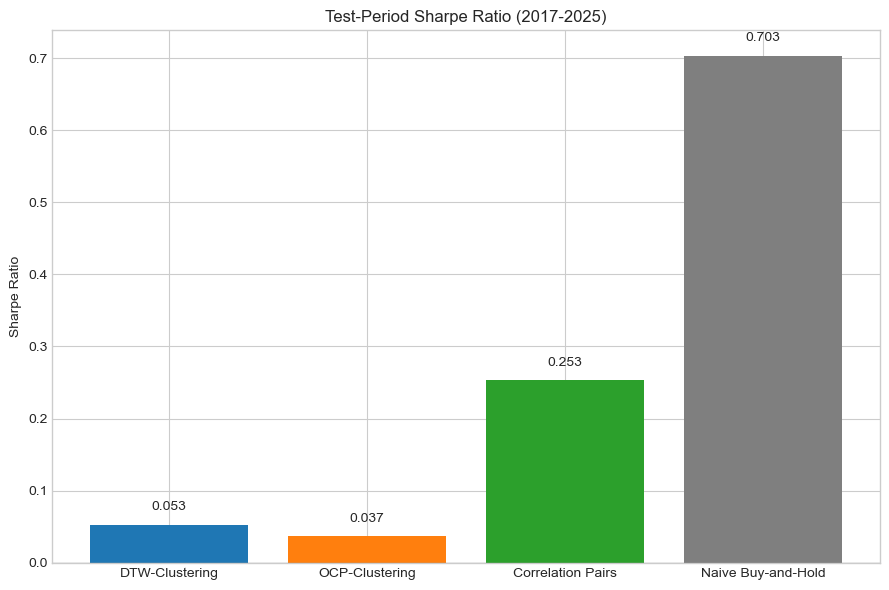

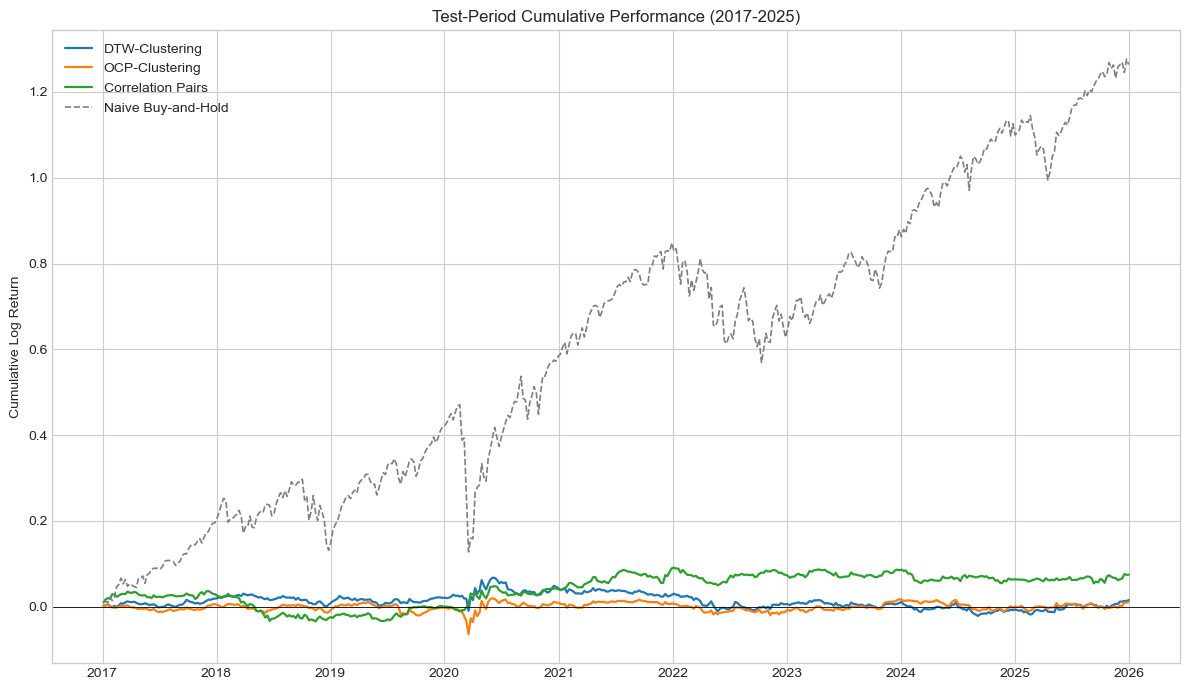

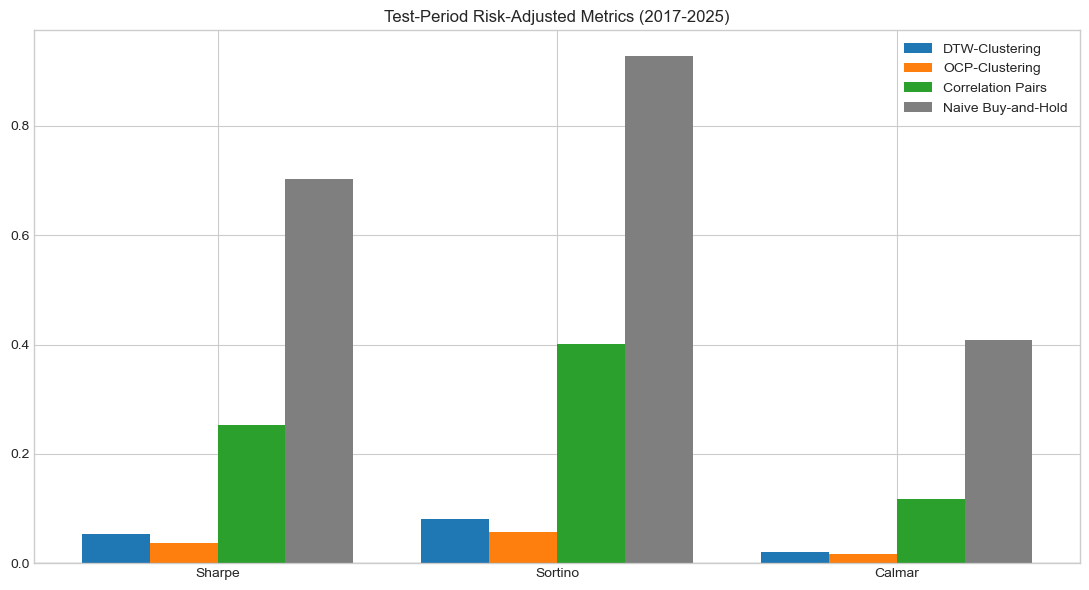

In [77]:
# Figures: Sharpe comparison, cumulative performance, risk-adjusted metrics
fig, ax = plt.subplots(figsize=(9, 6))
vals = test_table.set_index('strategy')['sharpe']
bars = ax.bar(vals.index, vals.values, color=[COLORS[s] for s in STRATS])
for b_ in bars:
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 0.02, f'{b_.get_height():.3f}', ha='center')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Sharpe Ratio')
ax.set_title(f'Test-Period Sharpe Ratio ({TEST_START[:4]}-{TEST_END[:4]})')
plt.tight_layout()
plt.savefig(f'sharpe_comparison_test_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(12, 7))
for s in STRATS:
    c = test_returns[s].cumsum()
    ax.plot(c.index, c.values, label=LABELS[s], color=COLORS[s],
            linewidth=1.6 if s != 'Naive' else 1.2, linestyle='-' if s != 'Naive' else '--')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_ylabel('Cumulative Log Return')
ax.set_title(f'Test-Period Cumulative Performance ({TEST_START[:4]}-{TEST_END[:4]})')
ax.legend()
plt.tight_layout()
plt.savefig(f'cumulative_pnl_test_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
mets = ['sharpe', 'sortino', 'calmar']
w = 0.2
x = np.arange(len(mets))
for i, s in enumerate(STRATS):
    v = test_table.set_index('strategy').loc[LABELS[s], mets].values.astype(float)
    ax.bar(x + (i - 1.5) * w, v, w, label=LABELS[s], color=COLORS[s])
ax.set_xticks(x); ax.set_xticklabels(['Sharpe', 'Sortino', 'Calmar'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(f'Test-Period Risk-Adjusted Metrics ({TEST_START[:4]}-{TEST_END[:4]})')
ax.legend()
plt.tight_layout()
plt.savefig(f'risk_adjusted_metrics_test_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()